# AV2: Seleção de contexto com Programação Dinâmica

## 1. Instalação e configurações
Instala as bibliotecas e define os parâmetros, as consultas e as pastas usadas no experimento.

Responsável: Iris Azenate Ferreira

In [2]:
%pip -q install pandas numpy matplotlib nltk acl-anthology tiktoken sentence-transformers scikit-learn

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [10]:
import json
import math
import platform
import random
import re
import subprocess
import sys
import time
import tracemalloc
from collections import Counter, defaultdict
from pathlib import Path
import importlib.metadata as metadata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tiktoken
from IPython.display import display
from nltk.stem import PorterStemmer

SEMENTE = 42
SEED = SEMENTE  # nome usado nos testes
random.seed(SEMENTE)
np.random.seed(SEMENTE)

PASTA_DADOS = Path('dados')
PASTA_SAIDA = Path('resultados_av2')
PASTA_DADOS.mkdir(exist_ok=True)
PASTA_SAIDA.mkdir(exist_ok=True)
ARQUIVO_CORPUS = PASTA_DADOS / 'acl_corpus_av1.csv'

N_ARTIGOS_COLETA = 18000
ESCALAS_CORPUS = [500, 1000]  # duas quantidades de artigos
ESCALAS_CANDIDATOS = [20, 50]  # quantos resultados chegam à mochila
REPETICOES = 3
CONSULTAS_EXPERIMENTO = ['Q1', 'Q3', 'Q5']

TOKENIZADOR_NOME = 'cl100k_base'
ENC = tiktoken.get_encoding(TOKENIZADOR_NOME)
QUERY_TERMS = ['retrieval augmented generation', 'information retrieval', 'large language model']
QUERIES = {
    'Q1': 'What information retrieval methods are used in RAG systems?',
    'Q2': 'Which studies compare sparse retrieval and dense retrieval?',
    'Q3': 'What semantic search techniques are used to retrieve context for language models?',
    'Q4': 'What reranking methods are used in retrieval systems for LLMs?',
    'Q5': 'What metrics are used to evaluate Retrieval-Augmented Generation systems?',
    'Q6': 'Which papers use embeddings for document retrieval?',
    'Q7': 'What techniques are used to select the most relevant documents or excerpts for a language model?',
    'Q8': 'Which methods were compared for context retrieval?',
    'Q9': 'What limitations of RAG systems are reported in the articles?',
    'Q10': 'What chunking strategies are used in document retrieval?'
}

print('Sistema:', platform.platform())
print('Python:', platform.python_version())

Sistema: Linux-6.6.159+-x86_64-with-glibc2.39
Python: 3.13.18


## 2. Corpus da AV1
Carrega os artigos a partir do CSV ou, se ele não existir, coleta os artigos na ACL Anthology.

Responsável: Iris Azenate Ferreira

In [4]:
def contar_termos(texto, termos):
    """Pontuação para filtrar artigos na coleta inicial."""
    return sum(texto.count(termo) for termo in termos)


def baixar_artigos_acl(termos, quantidade):
    from acl_anthology import Anthology

    biblioteca = Anthology.from_repo()
    encontrados = []
    for artigo in biblioteca.papers():
        if artigo.title is None or artigo.abstract is None:
            continue

        titulo = str(artigo.title)
        resumo = str(artigo.abstract)
        pontos = contar_termos((titulo + ' ' + resumo).lower(), termos)
        if pontos > 0:
            encontrados.append({
                'id': str(artigo.full_id), 'title': titulo,
                'abstract': resumo, 'year': artigo.year,
                'doi': str(artigo.doi or ''), 'url': str(artigo.web_url),
                'pontos_coleta': pontos
            })

    encontrados.sort(key=lambda x: (x['pontos_coleta'], int(x['year'] or 0)), reverse=True)
    return pd.DataFrame(encontrados[:quantidade]).drop(columns='pontos_coleta')


if ARQUIVO_CORPUS.exists():
    df = pd.read_csv(ARQUIVO_CORPUS, dtype={'id': str})
    origem = 'CSV da AV1'
else:
    try:
        df = baixar_artigos_acl(QUERY_TERMS, N_ARTIGOS_COLETA)
    df.to_csv(ARQUIVO_CORPUS, index=False)
    origem = 'Nova coleta da ACL Anthology'

colunas = {'id', 'title', 'abstract', 'year', 'url'}
assert colunas.issubset(df.columns), 'O CSV não contém todas as colunas necessárias.'
df = df.dropna(subset=['id', 'title', 'abstract'])
df = df.drop_duplicates(subset='id').reset_index(drop=True)
assert len(df) >= max(ESCALAS_CORPUS), 'São necessários pelo menos 1000 artigos reais.'

print('Origem:', origem, '| Artigos:', len(df))
display(df[['id', 'title', 'year']].head())

/usr/local/lib/python3.13/dist-packages/acl_anthology/text/texmath.py:211: TeXParserWarning: Unknown TeX-math command: \choose
  warnings.warn(TeXParserWarning(code, f"Unknown TeX-math command: {code}"))
/usr/local/lib/python3.13/dist-packages/acl_anthology/text/texmath.py:211: TeXParserWarning: Unknown TeX-math command: \textcolor{red}{100~trillion}
  warnings.warn(TeXParserWarning(code, f"Unknown TeX-math command: {code}"))
/usr/local/lib/python3.13/dist-packages/acl_anthology/text/texmath.py:211: TeXParserWarning: Unknown TeX-math command: \binom{62}{6}
  warnings.warn(TeXParserWarning(code, f"Unknown TeX-math command: {code}"))
/usr/local/lib/python3.13/dist-packages/acl_anthology/text/texmath.py:211: TeXParserWarning: Unknown TeX-math command: \textcolor{red}{WARNING: This paper contains examples of harmful or inappropriate images generated by models.}
  warnings.warn(TeXParserWarning(code, f"Unknown TeX-math command: {code}"))
/usr/local/lib/python3.13/dist-packages/acl_anthology

Origem: Nova coleta da ACL Anthology | Artigos: 18000


,id,title,year
0,2025.findings-emnlp.989,LlmFixer: Fix the Helpfulness of Defensive Lar...,2025
1,2024.findings-naacl.43,Measuring Social Norms of Large Language Models,2024
2,2025.emnlp-main.1006,Flaw or Artifact? Rethinking Prompt Sensitivit...,2025
3,2025.findings-naacl.27,CLaMP 2: Multimodal Music Information Retrieva...,2025
4,2025.findings-acl.1014,Evaluating the Long-Term Memory of Large Langu...,2025


## 3. Custos em tokens
Conta os tokens de cada artigo (título + resumo) com o tokenizador cl100k_base e mostra a distribuição dos custos.

Responsável: Iris Azenate Ferreira

,min,p25,mediana,p75,p90,max
0,45,206.0,236.0,267.0,297.0,853


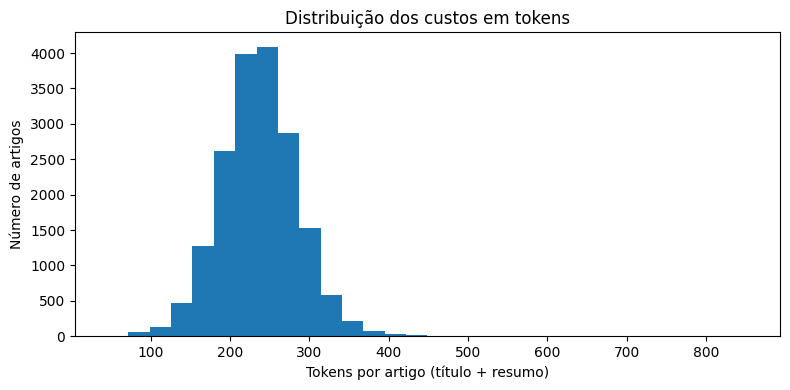

In [ ]:
def custo_tokens(texto):
    """Conta tokens reais do texto original (título + resumo), não palavras."""
    return len(ENC.encode(str(texto)))


custos = np.array([custo_tokens(str(t) + ' ' + str(a)) for t, a in zip(df['title'], df['abstract'])], dtype=int)
assert (custos > 0).all()

estat_custos = pd.DataFrame([{
    'min': int(custos.min()), 'p25': float(np.percentile(custos, 25)),
    'mediana': float(np.median(custos)), 'p75': float(np.percentile(custos, 75)),
    'p90': float(np.percentile(custos, 90)), 'max': int(custos.max())
}])
display(estat_custos)

plt.figure(figsize=(8, 4))
plt.hist(custos, bins=30)
plt.xlabel('Tokens por artigo (título + resumo)')
plt.ylabel('Número de artigos')
plt.title('Distribuição dos custos em tokens')
plt.tight_layout()
plt.savefig(PASTA_SAIDA / 'histograma_tokens.png', dpi=150)
plt.show()

## 4. Problema da mochila e orçamento W
Trata a seleção como mochila 0/1 (capacidade = W, peso = tokens do artigo, valor = score) e define os dois orçamentos W a partir da mediana dos custos.

Responsável: Clariane

In [ ]:
# Orçamentos de contexto: 3 e 6 vezes a mediana dos custos.
mediana = int(np.median(custos))
ORCAMENTOS = sorted({max(1, 3 * mediana), max(2, 6 * mediana)})
assert len(ORCAMENTOS) == 2

resumo_orc = pd.DataFrame([{
    'W': w, 'chunks_maiores_que_W': int((custos > w).sum()),
    'proporcao': float((custos > w).mean())
} for w in ORCAMENTOS])
display(resumo_orc)

,W,chunks_maiores_que_W,proporcao
0,708,2,0.000111
1,1416,0,0.000000


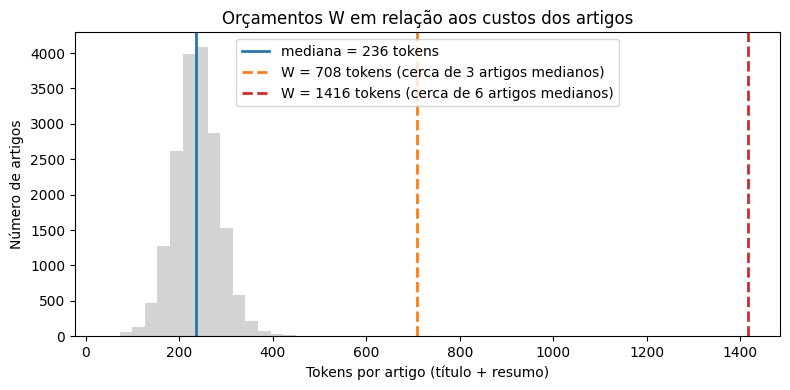

In [ ]:
# Gráfico: onde os orçamentos W caem na distribuição real dos custos.
plt.figure(figsize=(8, 4))
plt.hist(custos, bins=30, color='lightgray')
plt.axvline(mediana, color='tab:blue', linewidth=2, label=f'mediana = {mediana} tokens')
for w, cor in zip(ORCAMENTOS, ['tab:orange', 'tab:red']):
    plt.axvline(w, color=cor, linestyle='--', linewidth=2, label=f'W = {w} tokens (cerca de {w // mediana} artigos medianos)')
plt.xlabel('Tokens por artigo (título + resumo)')
plt.ylabel('Número de artigos')
plt.title('Orçamentos W em relação aos custos dos artigos')
plt.legend()
plt.tight_layout()
plt.savefig(PASTA_SAIDA / 'orcamentos_w.png', dpi=150)
plt.show()

## 5. Pré-requisitos: validação e formato da saída
Rejeita entradas que quebrariam a mochila e define o dicionário padrão que os três métodos devolvem (ids, tokens, valor e n).

Responsável: Clariane

In [ ]:
def validar_entrada(itens, W):
    """Evita entradas que quebrariam a mochila."""
    if not isinstance(W, (int, np.integer)) or W < 0:
        raise ValueError('W deve ser inteiro e não negativo')
    ids = [str(a['id']) for a in itens]
    if len(ids) != len(set(ids)):
        raise ValueError('IDs duplicados')
    for artigo in itens:
        if not isinstance(artigo['cost'], (int, np.integer)) or artigo['cost'] <= 0:
            raise ValueError('Tokens devem ser inteiros positivos')
        if not np.isfinite(artigo['value']) or artigo['value'] < 0:
            raise ValueError('Pontuação inválida')


def resposta(escolhidos):
    return {
        'ids': [a['id'] for a in escolhidos],
        'tokens': sum(int(a['cost']) for a in escolhidos),
        'valor': sum(float(a['value']) for a in escolhidos),
        'n': len(escolhidos)
    }

## 6. Busca da AV1 e candidatos
Reaproveita a normalização e o índice invertido da AV1 para gerar os candidatos de cada consulta, com o score que vira o valor na mochila.

Responsável: José Nilton

In [ ]:
stemmer = PorterStemmer()
STOPWORDS = {'the','and','or','of','to','a','in','for','on','with','as','is','are','was','were','what','which','how'}


def palavras(texto):
    """Coloca texto em minúsculas e reduz palavras ao radical (AV1)."""
    texto = re.sub(r'[^a-z0-9\s]', ' ', str(texto).lower())
    return [stemmer.stem(p) for p in texto.split()]


def palavras_da_consulta(pergunta):
    return [p for p in palavras(pergunta) if p not in STOPWORDS]


def preparar_documentos(tabela):
    documentos_prontos = []
    for artigo in tabela.itertuples(index=False):
        texto = str(artigo.title) + ' ' + str(artigo.abstract)
        documentos_prontos.append({
            'id': str(artigo.id), 'title': str(artigo.title),
            'text': texto, 'tokens': palavras(texto),
            'cost': custo_tokens(texto), 'url': str(artigo.url),
            'year': artigo.year
        })
    return documentos_prontos


def construir_indice_invertido(docs):
    """Termo -> posições dos artigos que contêm esse termo."""
    indice = defaultdict(set)
    for posicao, artigo in enumerate(docs):
        for termo in set(artigo['tokens']):
            indice[termo].add(posicao)
    return indice


def buscar_candidatos(docs, indice, consulta, top_n=50):
    """Busca artigos e ordena pela quantidade de termos da pergunta."""
    termos = palavras_da_consulta(consulta)
    if not termos or top_n <= 0:
        return []

    posicoes = set()
    for termo in termos:
        posicoes.update(indice.get(termo, set()))

    candidatos = []
    for posicao in posicoes:
        artigo = docs[posicao]
        frequencias = Counter(artigo['tokens'])
        pontos = sum(frequencias[termo] for termo in termos)
        if pontos > 0:
            candidatos.append({**artigo, 'value': float(pontos)})

    candidatos.sort(key=lambda a: (-a['value'], a['id']))
    return candidatos[:top_n]


documentos = preparar_documentos(df)
assert len({d['id'] for d in documentos}) == len(documentos)
assert all(d['cost'] > 0 for d in documentos)
print('Artigos preparados:', len(documentos))

# Nome usado nas células de testes e avaliação.
tokenizar_lexical = palavras

Artigos preparados: 17990


## 7. Métodos de seleção: ranking e guloso
Implementa as duas baselines: o ranking da AV1 até encher W e o guloso por score dividido por tokens.

Responsável: José Nilton

In [ ]:
def ranking_av1(itens, W):
    """Baseline: tenta os artigos com maiores pontuações primeiro."""
    validar_entrada(itens, W)
    ordem = sorted(itens, key=lambda a: (-a['value'], a['id']))
    escolhidos = []
    espaco_livre = W
    for artigo in ordem:
        if artigo['value'] > 0 and artigo['cost'] <= espaco_livre:
            escolhidos.append(artigo)
            espaco_livre -= artigo['cost']
    return resposta(escolhidos)


def guloso_razao(itens, W):
    """Guloso: prefere maior pontuação dividida pelo custo."""
    validar_entrada(itens, W)
    ordem = sorted(itens, key=lambda a: (-a['value']/a['cost'], -a['value'], a['id']))
    escolhidos = []
    espaco_livre = W
    for artigo in ordem:
        if artigo['value'] > 0 and artigo['cost'] <= espaco_livre:
            escolhidos.append(artigo)
            espaco_livre -= artigo['cost']
    return resposta(escolhidos)

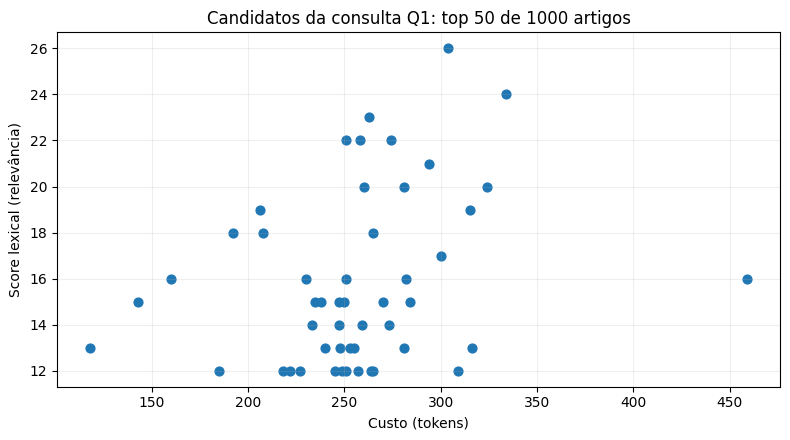

In [ ]:
# Gráfico: custo × score dos candidatos de uma consulta (os "itens" da mochila).
docs_ex = preparar_documentos(df.iloc[:max(ESCALAS_CORPUS)])
indice_ex = construir_indice_invertido(docs_ex)
qid_ex = CONSULTAS_EXPERIMENTO[0]
cand_ex = buscar_candidatos(docs_ex, indice_ex, QUERIES[qid_ex], max(ESCALAS_CANDIDATOS))

plt.figure(figsize=(8, 4.5))
plt.scatter([c['cost'] for c in cand_ex], [c['value'] for c in cand_ex], s=40, color='tab:blue')
plt.xlabel('Custo (tokens)')
plt.ylabel('Score lexical (relevância)')
plt.title(f'Candidatos da consulta {qid_ex}: top {len(cand_ex)} de {max(ESCALAS_CORPUS)} artigos')
plt.grid(alpha=.2)
plt.tight_layout()
plt.savefig(PASTA_SAIDA / 'candidatos_custo_score.png', dpi=150)
plt.show()

## 8. Programação dinâmica e busca exaustiva
Implementa a mochila 0/1 por programação dinâmica, com reconstrução dos IDs escolhidos, e a busca exaustiva usada como gabarito.

Responsável: Leonardo

In [ ]:
def mochila_dp(itens, W):
    """Programação dinâmica: encontra a melhor soma de pontuações."""
    validar_entrada(itens, W)
    quantidade = len(itens)

    # Tabela de valores e tabela para lembrar quais artigos foram escolhidos.
    tabela = np.zeros((quantidade + 1, W + 1))
    escolhido = np.zeros((quantidade + 1, W + 1), dtype=bool)

    for i, artigo in enumerate(itens, start=1):
        custo = int(artigo['cost'])
        pontos = float(artigo['value'])

        # Começa com a opção de NÃO pegar o artigo atual.
        tabela[i] = tabela[i - 1]
        if custo > W or pontos == 0:
            continue

        # Se pegar o artigo, o valor é o anterior + pontos dele.
        # O fatiamento faz a comparação para todos os orçamentos de uma vez.
        valor_se_pegar = tabela[i - 1, :W + 1 - custo] + pontos
        valor_sem_pegar = tabela[i, custo:]
        vale_a_pena = valor_se_pegar > valor_sem_pegar + 1e-10

        tabela[i, custo:] = np.where(vale_a_pena, valor_se_pegar, valor_sem_pegar)
        escolhido[i, custo:] = vale_a_pena

    # Caminha do final da tabela até o início para descobrir os IDs.
    espaco = W
    artigos_escolhidos = []
    for i in range(quantidade, 0, -1):
        if escolhido[i, espaco]:
            artigo = itens[i - 1]
            artigos_escolhidos.append(artigo)
            espaco -= int(artigo['cost'])

    artigos_escolhidos.reverse()
    resultado = resposta(artigos_escolhidos)
    assert resultado['tokens'] <= W
    assert math.isclose(resultado['valor'], tabela[quantidade, W], abs_tol=1e-7)
    return resultado


def exaustiva(itens, W):
    """Confere todas as combinações (somente para testes pequenos)."""
    validar_entrada(itens, W)
    if len(itens) > 20:
        raise ValueError('Use no máximo 20 artigos na busca exaustiva')

    melhor = resposta([])
    for mascara in range(2 ** len(itens)):
        escolhidos = [a for i, a in enumerate(itens) if mascara & (1 << i)]
        atual = resposta(escolhidos)
        if atual['tokens'] <= W and atual['valor'] > melhor['valor'] + 1e-10:
            melhor = atual
    return melhor


METODOS = {
    'Ranking AV1': ranking_av1,
    'Guloso razão': guloso_razao,
    'DP mochila 0/1': mochila_dp
}

## 9. Testes
Executa os testes de corretude, incluindo casos de borda, o caso em que o guloso perde e a comparação com a busca exaustiva.

Responsável: Leonardo

In [ ]:
def item(i,c,v,text=None):
    return {'id':str(i),'cost':c,'value':v,'text':text or str(i),'tokens':tokenizar_lexical(text or str(i))}

def testar():
    testes=[]
    def verificar(nome,entrada,W,esperado,criterio,requisito):
        try:
            resultado=mochila_dp(entrada,W)
            observado={'valor':resultado['valor'],'tokens':resultado['tokens'],'ids':resultado['ids']}
            ok=bool(criterio(resultado))
            testes.append({'teste':nome,'esperado':esperado,'observado':str(observado),
                           'status':'PASSOU' if ok else 'FALHOU','requisito':requisito})
        except Exception as e:
            testes.append({'teste':nome,'esperado':esperado,'observado':repr(e),'status':'FALHOU','requisito':requisito})
    verificar('1. normal',[item('A',3,4),item('B',4,5),item('C',2,3)],5,'valor 7, A+C',lambda r:math.isclose(r['valor'],7) and set(r['ids'])=={'A','C'},'ótimo e restrição')
    verificar('2. corpus vazio',[],10,'conjunto vazio',lambda r:r['n']==0,'vazio')
    verificar('3. W=0',[item('A',2,4)],0,'conjunto vazio',lambda r:r['n']==0,'fronteira')
    verificar('4. custo igual W',[item('A',5,3)],5,'seleciona A',lambda r:r['ids']==['A'],'fronteira exata')
    verificar('5. item maior W',[item('A',6,9)],5,'não seleciona',lambda r:r['n']==0,'inviável')
    verificar('6. empate',[item('A',2,5),item('B',2,5)],2,'valor 5 e um ID',lambda r:r['valor']==5 and r['n']==1,'empate')
    verificar('7. score zero',[item('A',1,0)],5,'conjunto vazio',lambda r:r['n']==0,'relevância nula')
    verificar('8. entrada grande',[item(f'I{i}',i%7+1,float(i%5+1)) for i in range(70)],400,'igual ao total (tudo cabe)',lambda r:r['n']==70,'escalabilidade')
    exemplo=[item('A',10,60),item('B',20,100),item('C',30,120)]
    verificar('9. adversarial',exemplo,50,'DP valor 220',lambda r:r['valor']==220 and set(r['ids'])=={'B','C'},'refutação guloso')
    verificar('10. consulta sem correspondência',[],25,'vazio',lambda r:r['n']==0,'sem candidatos')
    # ID duplicado deve ser rejeitado explicitamente
    try:
        mochila_dp([item('dup',1,5),item('dup',2,6)],3)
        passou=False; obs='não gerou erro'
    except ValueError as e: passou=True;obs=str(e)
    testes.append({'teste':'11. IDs duplicados','esperado':'ValueError','observado':obs,
                   'status':'PASSOU' if passou else 'FALHOU','requisito':'deduplicação'})
    # Comparação com exaustiva em instâncias pequenas aleatórias
    rng=random.Random(SEED)
    ok=True
    for rodada in range(30):
        xs=[item(f'{rodada}-{j}',rng.randint(1,12),rng.randint(0,15)) for j in range(rng.randint(0,12))]
        w=rng.randint(0,40)
        if not math.isclose(mochila_dp(xs,w)['valor'],exaustiva(xs,w)['valor'],abs_tol=1e-7):ok=False;break
    testes.append({'teste':'12. DP × exaustiva (30 instâncias)','esperado':'mesmo valor ótimo nas 30',
                  'observado':'30 concordâncias' if ok else f'divergência na rodada {rodada}',
                  'status':'PASSOU' if ok else 'FALHOU','requisito':'corretude'})
    tabela=pd.DataFrame(testes)
    assert (tabela['status']=='PASSOU').all(), 'Falha nos testes: revisar antes do experimento.'
    return tabela,exemplo

tabela_testes,exemplo_adversarial=testar()
display(tabela_testes)
tabela_testes.to_csv(PASTA_SAIDA/'testes.csv',index=False)
print('Adversarial:', {k:f(exemplo_adversarial,50) for k,f in METODOS.items()})

,teste,esperado,observado,status,requisito
0,1. normal,"valor 7, A+C","{'valor': 7.0, 'tokens': 5, 'ids': ['A', 'C']}",PASSOU,ótimo e restrição
1,2. corpus vazio,conjunto vazio,"{'valor': 0, 'tokens': 0, 'ids': []}",PASSOU,vazio
2,3. W=0,conjunto vazio,"{'valor': 0, 'tokens': 0, 'ids': []}",PASSOU,fronteira
3,4. custo igual W,seleciona A,"{'valor': 3.0, 'tokens': 5, 'ids': ['A']}",PASSOU,fronteira exata
4,5. item maior W,não seleciona,"{'valor': 0, 'tokens': 0, 'ids': []}",PASSOU,inviável
5,6. empate,valor 5 e um ID,"{'valor': 5.0, 'tokens': 2, 'ids': ['A']}",PASSOU,empate
6,7. score zero,conjunto vazio,"{'valor': 0, 'tokens': 0, 'ids': []}",PASSOU,relevância nula
7,8. entrada grande,igual ao total (tudo cabe),"{'valor': 210.0, 'tokens': 280, 'ids': ['I0', ...",PASSOU,escalabilidade
8,9. adversarial,DP valor 220,"{'valor': 220.0, 'tokens': 50, 'ids': ['B', 'C']}",PASSOU,refutação guloso
9,10. consulta sem correspondência,vazio,"{'valor': 0, 'tokens': 0, 'ids': []}",PASSOU,sem candidatos


Adversarial: {'Ranking AV1': {'ids': ['C', 'B'], 'tokens': 50, 'valor': 220.0, 'n': 2}, 'Guloso razão': {'ids': ['A', 'B'], 'tokens': 30, 'valor': 160.0, 'n': 2}, 'DP mochila 0/1': {'ids': ['B', 'C'], 'tokens': 50, 'valor': 220.0, 'n': 2}}


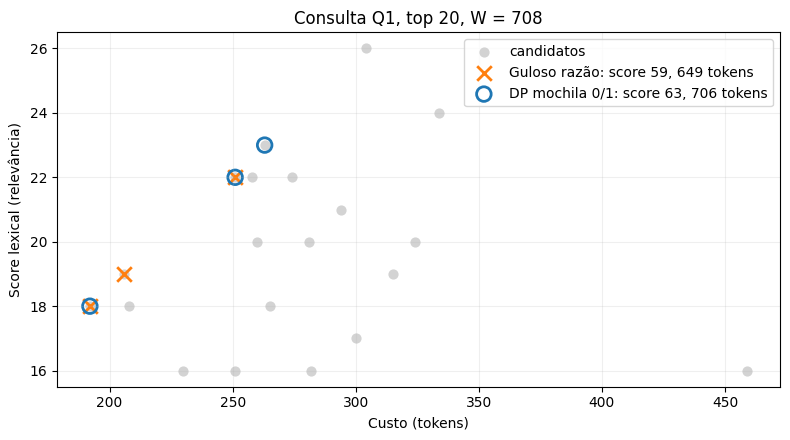

In [ ]:
# Gráfico: um caso REAL em que o guloso e a DP escolhem conjuntos diferentes.
caso = None
for qid in CONSULTAS_EXPERIMENTO:
    cands = buscar_candidatos(docs_ex, indice_ex, QUERIES[qid], max(ESCALAS_CANDIDATOS))
    for n in ESCALAS_CANDIDATOS:
        for W in ORCAMENTOS:
            g, d = guloso_razao(cands[:n], W), mochila_dp(cands[:n], W)
            if d['valor'] > g['valor'] + 1e-8:
                caso = (qid, n, W, cands[:n], g, d)
                break
        if caso: break
    if caso: break

if caso is None:
    print('Nenhum caso real em que a DP supera o guloso nestes parâmetros.')
else:
    qid, n, W, cands, g, d = caso
    plt.figure(figsize=(8, 4.5))
    plt.scatter([c['cost'] for c in cands], [c['value'] for c in cands], s=40, color='lightgray', label='candidatos')
    for res, cor, marca, nome in [(g, 'tab:orange', 'x', 'Guloso razão'), (d, 'tab:blue', 'o', 'DP mochila 0/1')]:
        esc = [c for c in cands if c['id'] in set(res['ids'])]
        plt.scatter([c['cost'] for c in esc], [c['value'] for c in esc], s=110, marker=marca,
                    facecolors='none' if marca == 'o' else cor, edgecolors=cor if marca == 'o' else None,
                    color=cor if marca == 'x' else None, linewidths=2,
                    label=f"{nome}: score {res['valor']:.0f}, {res['tokens']} tokens")
    plt.xlabel('Custo (tokens)')
    plt.ylabel('Score lexical (relevância)')
    plt.title(f'Consulta {qid}, top {n}, W = {W}')
    plt.legend()
    plt.grid(alpha=.2)
    plt.tight_layout()
    plt.savefig(PASTA_SAIDA / 'guloso_vs_dp_caso_real.png', dpi=150)
    plt.show()

## 10. Corretude
Justifica por indução que a DP encontra a seleção de maior score sem ultrapassar W.

Responsável: Leonardo

A DP preenche uma tabela T[i][w] = maior score possível usando só os i primeiros artigos com até w tokens.

Recorrência: T[0][w] = 0 e T[i][w] = T[i-1][w] se o custo do artigo i for maior que w; senão, T[i][w] = max(T[i-1][w], T[i-1][w - custo_i] + valor_i).

Corretude por indução em i: para i = 0 a tabela vale 0, que é o ótimo sem artigos. Supondo a linha i-1 correta, a solução ótima com i artigos ou não usa o artigo i (e vale T[i-1][w]) ou usa (e vale valor_i mais o ótimo da linha i-1 com o espaço restante). A recorrência escolhe o maior dos dois, então a linha i também é ótima. Logo T[N][W] é o ótimo, e a matriz de escolhas permite reconstruir os IDs sem repetir artigo e sem passar de W.

Evidência prática: a DP coincidiu com a busca exaustiva nas 30 instâncias aleatórias do teste 12.

## 11. Desenho experimental
Define as métricas e roda as 216 medições com os três métodos sobre as mesmas entradas.

Responsável: Thiago

In [ ]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
MODELO_SEMANTICO='sentence-transformers/all-MiniLM-L6-v2'
modelo_semantico=SentenceTransformer(MODELO_SEMANTICO)

def gabarito_semantico(docs,queries,top_n=15):
    # embeddings normalizados => produto interno = similaridade de cosseno
    emb_docs=modelo_semantico.encode([d['text'] for d in docs],batch_size=64,
                                    show_progress_bar=True,normalize_embeddings=True)
    saida={}
    for qid,q in queries.items():
        eq=modelo_semantico.encode([q],normalize_embeddings=True)[0]
        sims=emb_docs @ eq
        # desempate reprodutível por índice
        indices=np.lexsort((np.arange(len(sims)),-sims))[:top_n]
        saida[qid]={docs[int(i)]['id'] for i in indices}
    return saida

def redundancia_jaccard(selecionados):
    if len(selecionados)<2:return 0.0
    conjuntos=[set(x['tokens']) for x in selecionados]
    pares=[]
    for i in range(len(conjuntos)):
        for j in range(i+1,len(conjuntos)):
            u=conjuntos[i]|conjuntos[j]
            pares.append(len(conjuntos[i]&conjuntos[j])/len(u) if u else 0.0)
    return float(np.mean(pares))

def metricas_selecao(res,candidatos,relevantes,W):
    mapa={x['id']:x for x in candidatos}
    escolhidos=[mapa[i] for i in res['ids']]
    ordenados=sorted(escolhidos,key=lambda x:(-x['value'],x['id']))
    acertos=sum(x['id'] in relevantes for x in escolhidos)
    return {'tokens_usados':res['tokens'],'valor_total':res['valor'],'n_selecionados':res['n'],
            'respeita_W':res['tokens']<=W,'precision_selecionados':acertos/len(escolhidos) if escolhidos else 0.0,
            'precision_at_5':sum(x['id'] in relevantes for x in ordenados[:5])/5,
            'redundancia_jaccard':redundancia_jaccard(escolhidos)}

c:\Users\victo\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2297.32it/s]


In [ ]:
def medir_pico_python(func,*args):
    tracemalloc.start()
    try:
        func(*args)
        _,pico=tracemalloc.get_traced_memory()
    finally:
        tracemalloc.stop()
    return pico/1024**2

linhas=[];preparacoes=[];candidatos_cache={};gabaritos_cache={}
for tamanho in ESCALAS_CORPUS:
    fatia=df.iloc[:tamanho].copy()
    t0=time.perf_counter();docs=preparar_documentos(fatia);t_pre=time.perf_counter()-t0
    t0=time.perf_counter();indice=construir_indice_invertido(docs);t_ind=time.perf_counter()-t0
    preparacoes.append({'corpus':tamanho,'preprocessamento_s':t_pre,'indice_s':t_ind,
                         'n_chunks':len(docs),'n_termos_indice':len(indice)})
    print(f'Escala {tamanho}: gerando gabarito semântico independente...')
    gab=gabarito_semantico(docs,{k:QUERIES[k] for k in CONSULTAS_EXPERIMENTO},15)
    gabaritos_cache[tamanho]=gab
    for qid in CONSULTAS_EXPERIMENTO:
        consulta=QUERIES[qid]
        t0=time.perf_counter();full=buscar_candidatos(docs,indice,consulta,max(ESCALAS_CANDIDATOS))
        t_busca=time.perf_counter()-t0
        for n_cand in ESCALAS_CANDIDATOS:
            cand=full[:n_cand]
            candidatos_cache[(tamanho,qid,n_cand)]=cand
            for W in ORCAMENTOS:
                for nome,algoritmo in METODOS.items():
                    for repeticao in range(1,REPETICOES+1):
                        t0=time.perf_counter();res=algoritmo(cand,W)
                        t_sel=time.perf_counter()-t0
                        mem=medir_pico_python(algoritmo,cand,W)
                        met=metricas_selecao(res,cand,gab[qid],W)
                        assert met['respeita_W']
                        linhas.append({'corpus':tamanho,'query_id':qid,'consulta':consulta,
                         'n_candidatos_solicitados':n_cand,'n_candidatos_reais':len(cand),
                         'W':W,'algoritmo':nome,'repeticao':repeticao,
                         'tempo_preprocessamento_s':t_pre,'tempo_indice_s':t_ind,
                         'tempo_busca_s':t_busca,'tempo_selecao_s':t_sel,
                         'tempo_total_estimado_s':t_pre+t_ind+t_busca+t_sel,
                         'pico_memoria_python_mb':mem,'ids_selecionados':json.dumps(res['ids']),**met})

medicoes=pd.DataFrame(linhas)
preparacoes_df=pd.DataFrame(preparacoes)
assert len(medicoes)==len(ESCALAS_CORPUS)*len(CONSULTAS_EXPERIMENTO)*len(ESCALAS_CANDIDATOS)*len(ORCAMENTOS)*len(METODOS)*REPETICOES
assert medicoes['respeita_W'].all()
medicoes.to_csv(PASTA_SAIDA/'medicoes_brutas.csv',index=False)
preparacoes_df.to_csv(PASTA_SAIDA/'preparacao.csv',index=False)
print('Medições:',len(medicoes));display(medicoes.head(10))

Escala 500: gerando gabarito semântico independente...


Batches: 100%|██████████| 8/8 [00:24<00:00,  3.05s/it]


Escala 1000: gerando gabarito semântico independente...


Batches: 100%|██████████| 16/16 [00:45<00:00,  2.83s/it]


Medições: 216


,corpus,query_id,consulta,n_candidatos_solicitados,n_candidatos_reais,W,algoritmo,repeticao,tempo_preprocessamento_s,tempo_indice_s,...,tempo_total_estimado_s,pico_memoria_python_mb,ids_selecionados,tokens_usados,valor_total,n_selecionados,respeita_W,precision_selecionados,precision_at_5,redundancia_jaccard
0,500,Q1,What information retrieval methods are used in...,20,20,708,Ranking AV1,1,2.158358,0.041876,...,2.217147,0.002876,"[""2025.acl-long.1476"", ""2026.rail-1.6""]",638,50.0,2,True,1.0,0.4,0.203791
1,500,Q1,What information retrieval methods are used in...,20,20,708,Ranking AV1,2,2.158358,0.041876,...,2.217106,0.002876,"[""2025.acl-long.1476"", ""2026.rail-1.6""]",638,50.0,2,True,1.0,0.4,0.203791
2,500,Q1,What information retrieval methods are used in...,20,20,708,Ranking AV1,3,2.158358,0.041876,...,2.217096,0.002876,"[""2025.acl-long.1476"", ""2026.rail-1.6""]",638,50.0,2,True,1.0,0.4,0.203791
3,500,Q1,What information retrieval methods are used in...,20,20,708,Guloso razão,1,2.158358,0.041876,...,2.217106,0.002876,"[""L04-1241"", ""2024.emnlp-main.922"", ""2020.lrec...",603,56.0,3,True,0.0,0.0,0.176506
4,500,Q1,What information retrieval methods are used in...,20,20,708,Guloso razão,2,2.158358,0.041876,...,2.217104,0.002876,"[""L04-1241"", ""2024.emnlp-main.922"", ""2020.lrec...",603,56.0,3,True,0.0,0.0,0.176506
5,500,Q1,What information retrieval methods are used in...,20,20,708,Guloso razão,3,2.158358,0.041876,...,2.217103,0.002876,"[""L04-1241"", ""2024.emnlp-main.922"", ""2020.lrec...",603,56.0,3,True,0.0,0.0,0.176506
6,500,Q1,What information retrieval methods are used in...,20,20,708,DP mochila 0/1,1,2.158358,0.041876,...,2.217688,0.138624,"[""2023.ranlp-1.124"", ""2020.lrec-1.219"", ""2024....",706,63.0,3,True,0.0,0.0,0.194081
7,500,Q1,What information retrieval methods are used in...,20,20,708,DP mochila 0/1,2,2.158358,0.041876,...,2.217454,0.138624,"[""2023.ranlp-1.124"", ""2020.lrec-1.219"", ""2024....",706,63.0,3,True,0.0,0.0,0.194081
8,500,Q1,What information retrieval methods are used in...,20,20,708,DP mochila 0/1,3,2.158358,0.041876,...,2.217422,0.138624,"[""2023.ranlp-1.124"", ""2020.lrec-1.219"", ""2024....",706,63.0,3,True,0.0,0.0,0.194081
9,500,Q1,What information retrieval methods are used in...,20,20,1416,Ranking AV1,1,2.158358,0.041876,...,2.217148,0.002876,"[""2025.acl-long.1476"", ""2026.rail-1.6"", ""2023....",1410,117.0,5,True,0.4,0.4,0.188937


## 12. Resultados
Compara os métodos, resume as métricas por cenário e gera os gráficos.

Responsável: Thiago

In [ ]:
chaves=['corpus','query_id','n_candidatos_solicitados','W','repeticao']
comparacao=medicoes.pivot(index=chaves,columns='algoritmo',values='valor_total')
assert (comparacao['DP mochila 0/1']+1e-8>=comparacao['Guloso razão']).all()
assert (comparacao['DP mochila 0/1']+1e-8>=comparacao['Ranking AV1']).all()
comparacao['ganho_dp_vs_guloso']=comparacao['DP mochila 0/1']-comparacao['Guloso razão']
comparacao['ganho_dp_vs_ranking']=comparacao['DP mochila 0/1']-comparacao['Ranking AV1']
display(comparacao.reset_index().head(10))
print('Casos em que DP supera guloso:',int((comparacao.ganho_dp_vs_guloso>1e-8).sum()),'de',len(comparacao))
resumo=(medicoes.groupby(['corpus','n_candidatos_solicitados','W','algoritmo'],as_index=False)
        .agg(score_medio=('valor_total','mean'),tempo_selecao_medio_s=('tempo_selecao_s','mean'),
             pico_memoria_python_medio_mb=('pico_memoria_python_mb','mean'),
             tokens_medios=('tokens_usados','mean'),precisao_selecionados_media=('precision_selecionados','mean'),
             precision_at_5_media=('precision_at_5','mean'),redundancia_media=('redundancia_jaccard','mean')))
resumo.to_csv(PASTA_SAIDA/'resumo.csv',index=False)
display(resumo)

algoritmo,corpus,query_id,n_candidatos_solicitados,W,repeticao,DP mochila 0/1,Guloso razão,Ranking AV1,ganho_dp_vs_guloso,ganho_dp_vs_ranking
0,500,Q1,20,708,1,63.0,56.0,50.0,7.0,13.0
1,500,Q1,20,708,2,63.0,56.0,50.0,7.0,13.0
2,500,Q1,20,708,3,63.0,56.0,50.0,7.0,13.0
3,500,Q1,20,1416,1,123.0,123.0,117.0,0.0,6.0
4,500,Q1,20,1416,2,123.0,123.0,117.0,0.0,6.0
5,500,Q1,20,1416,3,123.0,123.0,117.0,0.0,6.0
6,500,Q1,50,708,1,68.0,62.0,50.0,6.0,18.0
7,500,Q1,50,708,2,68.0,62.0,50.0,6.0,18.0
8,500,Q1,50,708,3,68.0,62.0,50.0,6.0,18.0
9,500,Q1,50,1416,1,129.0,118.0,117.0,11.0,12.0


Casos em que DP supera guloso: 48 de 72


,corpus,n_candidatos_solicitados,W,algoritmo,score_medio,tempo_selecao_medio_s,pico_memoria_python_medio_mb,tokens_medios,precisao_selecionados_media,precision_at_5_media,redundancia_media
0,500,20,708,DP mochila 0/1,73.000000,0.000816,0.138386,700.000000,0.555556,0.333333,0.203967
1,500,20,708,Guloso razão,70.000000,0.000108,0.002876,657.666667,0.555556,0.333333,0.189335
2,500,20,708,Ranking AV1,60.333333,0.000123,0.002876,675.000000,0.722222,0.333333,0.194048
3,500,20,1416,DP mochila 0/1,135.666667,0.000695,0.277478,1405.666667,0.444444,0.466667,0.178006
4,500,20,1416,Guloso razão,130.000000,0.000114,0.002876,1296.000000,0.488889,0.533333,0.176333
5,500,20,1416,Ranking AV1,117.333333,0.000106,0.002876,1380.666667,0.566667,0.533333,0.182485
6,500,50,708,DP mochila 0/1,74.666667,0.001318,0.321566,699.333333,0.638889,0.400000,0.186611
7,500,50,708,Guloso razão,72.666667,0.000246,0.003090,669.000000,0.500000,0.333333,0.172290
8,500,50,708,Ranking AV1,60.333333,0.000235,0.003090,675.000000,0.722222,0.333333,0.194048
9,500,50,1416,DP mochila 0/1,139.666667,0.001493,0.642961,1394.666667,0.404762,0.400000,0.170199


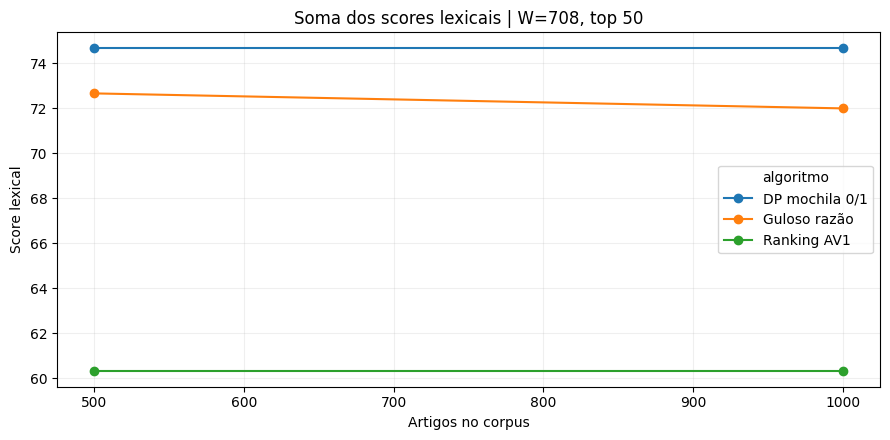

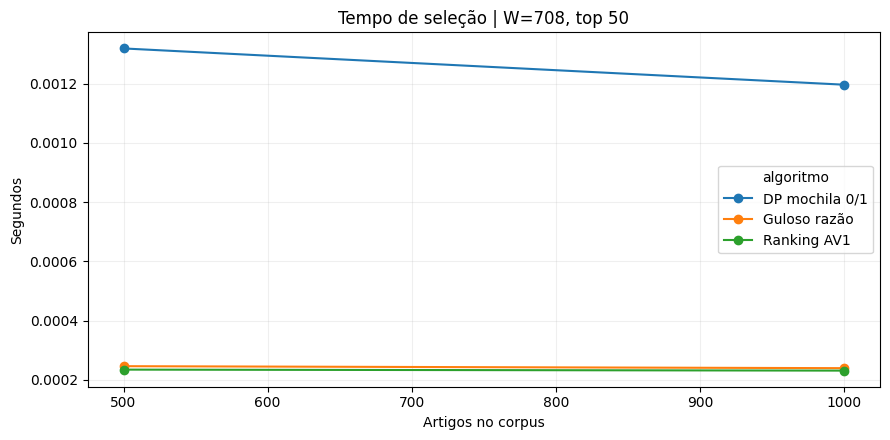

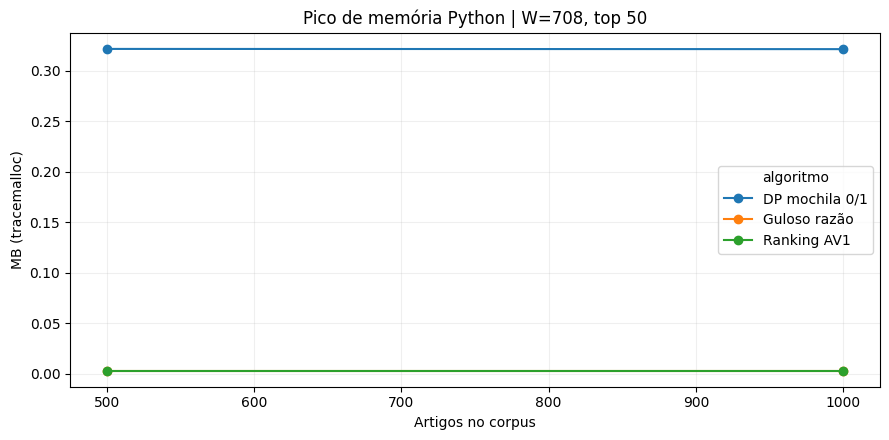

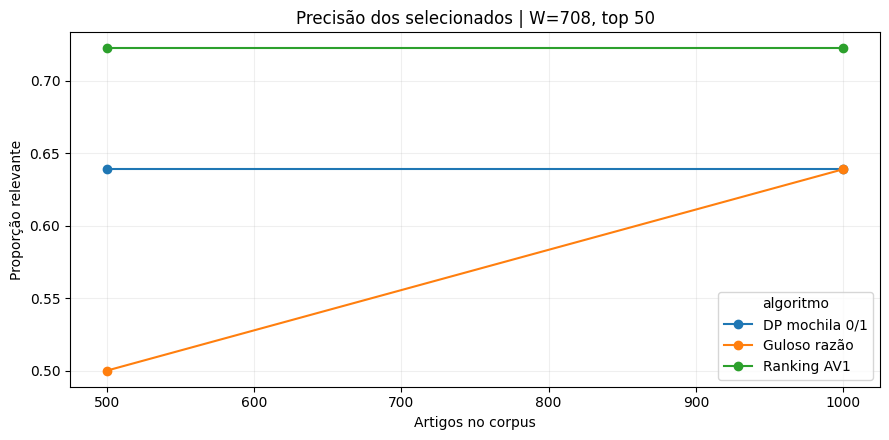

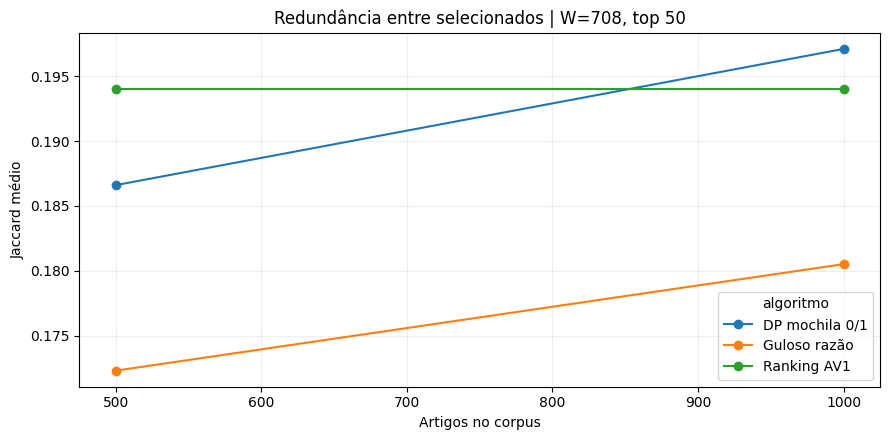

In [ ]:
for metrica,titulo,ylabel,arquivo in [
 ('valor_total','Soma dos scores lexicais','Score lexical','scores.png'),
 ('tempo_selecao_s','Tempo de seleção','Segundos','tempo_selecao.png'),
 ('pico_memoria_python_mb','Pico de memória Python','MB (tracemalloc)','memoria.png'),
 ('precision_selecionados','Precisão dos selecionados','Proporção relevante','precisao.png'),
 ('redundancia_jaccard','Redundância entre selecionados','Jaccard médio','redundancia.png')]:
    # Recorte coerente e fixo para leitura do gráfico (demais dados continuam no CSV)
    recorte=medicoes[(medicoes['W']==ORCAMENTOS[0]) &
                      (medicoes['n_candidatos_solicitados']==ESCALAS_CANDIDATOS[-1])]
    graf=recorte.groupby(['corpus','algoritmo'])[metrica].mean().unstack()
    ax=graf.plot(marker='o',figsize=(9,4.5))
    ax.set_title(f'{titulo} | W={ORCAMENTOS[0]}, top {ESCALAS_CANDIDATOS[-1]}')
    ax.set_xlabel('Artigos no corpus');ax.set_ylabel(ylabel);ax.grid(alpha=.2)
    plt.tight_layout();plt.savefig(PASTA_SAIDA/arquivo,dpi=150);plt.show()

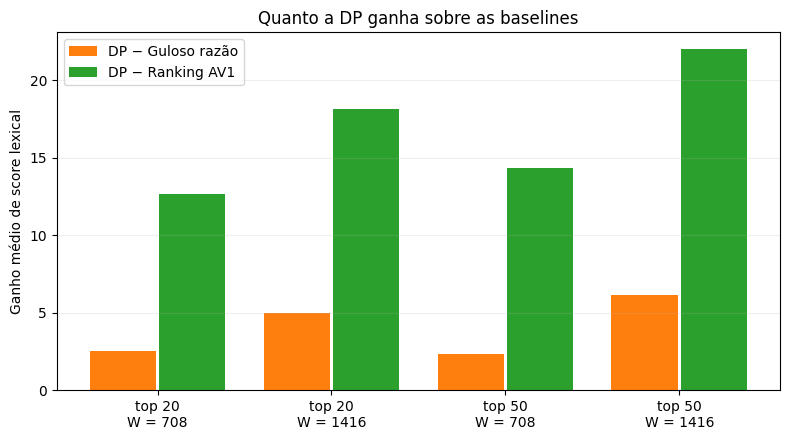

In [ ]:
# Gráfico: ganho médio de score da DP sobre as baselines em cada cenário.
ganho = comparacao.reset_index().groupby(['n_candidatos_solicitados', 'W'])[['ganho_dp_vs_guloso', 'ganho_dp_vs_ranking']].mean()
rotulos = [f'top {n}\nW = {w}' for n, w in ganho.index]
x = np.arange(len(ganho))
plt.figure(figsize=(8, 4.5))
plt.bar(x - 0.2, ganho['ganho_dp_vs_guloso'], width=0.38, color='tab:orange', label='DP − Guloso razão')
plt.bar(x + 0.2, ganho['ganho_dp_vs_ranking'], width=0.38, color='tab:green', label='DP − Ranking AV1')
plt.xticks(x, rotulos)
plt.ylabel('Ganho médio de score lexical')
plt.title('Quanto a DP ganha sobre as baselines')
plt.legend()
plt.grid(axis='y', alpha=.2)
plt.tight_layout()
plt.savefig(PASTA_SAIDA / 'ganho_dp.png', dpi=150)
plt.show()

## 13. Análise assintótica
Resume a complexidade dos métodos e mede o efeito de aumentar W com N fixo.

Responsável: Victoria Cardoso dos Santos

N = número de candidatos, W = orçamento inteiro de tokens, L = termos processados na construção do índice.

| Método | Tempo | Memória extra |
|---|---|---|
| Ranking AV1 | O(N log N) | O(N) |
| Guloso | O(N log N) | O(N) |
| DP implementada | O(N × W) | O(N × W) |
| Exaustiva (testes) | O(N × 2^N) | O(N) |
| Construção do índice | O(L) | O(L) |

A DP é pseudo-polinomial: o custo depende do valor de W, não do tamanho da entrada em bits. Com N fixo, dobrar W dobra o tempo e a memória da tabela. Tokenização, busca, embeddings e chamada ao LLM são custos à parte.

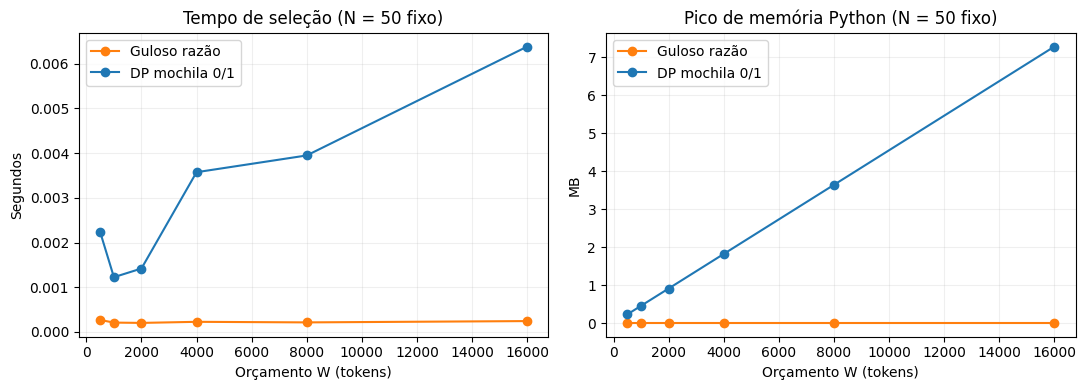

In [ ]:
# Gráfico: pseudo-polinomialidade na prática. N fixo, W aumentando.
cand_w = candidatos_cache[(ESCALAS_CORPUS[-1], CONSULTAS_EXPERIMENTO[0], ESCALAS_CANDIDATOS[-1])]
valores_w = [500, 1000, 2000, 4000, 8000, 16000]
linhas_w = []
for W in valores_w:
    for nome in ['Guloso razão', 'DP mochila 0/1']:
        tempos = []
        for _ in range(REPETICOES):
            t0 = time.perf_counter(); METODOS[nome](cand_w, W); tempos.append(time.perf_counter() - t0)
        linhas_w.append({'W': W, 'algoritmo': nome, 'tempo_s': float(np.median(tempos)),
                         'memoria_mb': medir_pico_python(METODOS[nome], cand_w, W)})
escala_w = pd.DataFrame(linhas_w)
escala_w.to_csv(PASTA_SAIDA / 'escala_w.csv', index=False)

fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
for nome, cor in [('Guloso razão', 'tab:orange'), ('DP mochila 0/1', 'tab:blue')]:
    parte = escala_w[escala_w['algoritmo'] == nome]
    eixos[0].plot(parte['W'], parte['tempo_s'], marker='o', color=cor, label=nome)
    eixos[1].plot(parte['W'], parte['memoria_mb'], marker='o', color=cor, label=nome)
eixos[0].set_title(f'Tempo de seleção (N = {len(cand_w)} fixo)'); eixos[0].set_ylabel('Segundos')
eixos[1].set_title(f'Pico de memória Python (N = {len(cand_w)} fixo)'); eixos[1].set_ylabel('MB')
for ax in eixos:
    ax.set_xlabel('Orçamento W (tokens)'); ax.grid(alpha=.2); ax.legend()
plt.tight_layout()
plt.savefig(PASTA_SAIDA / 'pseudo_polinomial_w.png', dpi=150)
plt.show()

## 14. Contexto para RAG e limitações
Monta o contexto que seria enviado ao LLM com os artigos escolhidos pela DP e resume as limitações do experimento.

Responsável: Victória Cardoso dos Santos

In [ ]:
tamanho_demo=ESCALAS_CORPUS[0];qid_demo=CONSULTAS_EXPERIMENTO[0];n_demo=ESCALAS_CANDIDATOS[0];W_demo=ORCAMENTOS[0]
cand_demo=candidatos_cache[(tamanho_demo,qid_demo,n_demo)]
sel_demo=mochila_dp(cand_demo,W_demo)
mapa_demo={x['id']:x for x in cand_demo}
blocos=[]
for cid in sel_demo['ids']:
    doc=mapa_demo[cid]
    blocos.append(f"[Fonte: {cid}] {doc['url']}\n{doc['text']}")
contexto='\n\n'.join(blocos)
print('Consulta:',QUERIES[qid_demo]);print('Chunks:',sel_demo['n'],'| Tokens dos textos:',sel_demo['tokens'],'| W:',W_demo)
print('Prévia do contexto (até 1500 caracteres):\n',contexto[:1500])
(PASTA_SAIDA/'contexto_exemplo.txt').write_text(contexto,encoding='utf-8')

Consulta: What information retrieval methods are used in RAG systems?
Chunks: 3 | Tokens dos textos: 706 | W: 708
Prévia do contexto (até 1500 caracteres):
 [Fonte: 2023.ranlp-1.124] https://aclanthology.org/2023.ranlp-1.124/
Auto-Encoding Questions with Retrieval Augmented Decoding for Unsupervised Passage Retrieval and Zero-Shot Question Generation Dense passage retrieval models have become state-of-the-art for information retrieval on many Open-domain Question Answering (ODQA) datasets. However, most of these models rely on supervision obtained from the ODQA datasets, which hinders their performance in a low-resource setting. Recently, retrieval-augmented language models have been proposed to improve both zero-shot and supervised information retrieval. However, these models have pre-training tasks that are agnostic to the target task of passage retrieval. In this work, we propose Retrieval Augmented Auto-encoding of Questions for zero-shot dense information retrieval. Unlike other p

4341

Limitações: a DP otimiza a soma dos scores lexicais, não a qualidade da resposta do LLM; a soma aditiva não desconta redundância; a busca lexical pode deixar de fora artigos relevantes, e a mochila não consegue recuperá-los; a contagem de tokens depende do tokenizador; o gabarito por embeddings é aproximado; W cobre só os textos dos artigos, sem pergunta e instruções; o experimento não chama um LLM, então não mede a qualidade da resposta gerada.

## 15. Reprodutibilidade
Salva sistema, versões, parâmetros para reproduzir o experimento.

Responsável: Victória Cardoso dos Santos

In [11]:

import hashlib
import json
import platform
import os
import pandas as pd
from importlib import metadata


# Bibliotecas utilizadas no notebook da AV2
bibliotecas = [
    'pandas',
    'numpy',
    'nltk',
    'matplotlib',
    'tiktoken',
    'sentence-transformers',
    'scikit-learn'
]


versoes_bibliotecas = {}

for biblioteca in bibliotecas:
    try:
        versoes_bibliotecas[biblioteca] = metadata.version(biblioteca)
    except metadata.PackageNotFoundError:
        versoes_bibliotecas[biblioteca] = 'não instalada'

# Hash SHA-256 do corpus
sha256 = hashlib.sha256(ARQUIVO_CORPUS.read_bytes()).hexdigest()

# Metadados do experimento
meta = {
    'data_geracao_metadados': pd.Timestamp.now(
        tz='America/Sao_Paulo'
    ).isoformat(),

    'sistema': platform.platform(),
    'python': platform.python_version(),

    'processador': platform.processor(),
    'cpus_logicas': os.cpu_count(),

    'versoes_bibliotecas': versoes_bibliotecas,

    'corpus_origem': origem,
    'arquivo_corpus': str(ARQUIVO_CORPUS),
    'sha256_corpus': sha256,
    'tamanho_corpus': len(df),

    'tokenizador': 'cl100k_base',

    'semente': 42,

    'repo_grupo': (
        'https://github.com/Leonardodcomp/'
        'PAA_UFS_2026_2_Ferreira_Iris_Ferreira_Jose_'
        'Lisboa_Clariane_Santos_Thiago_Santos_'
        'Victoria_Silva_Leo/tree/main/AV02'
    ),


    'execucao': (
        'Executar todas as células em ordem no '
        'Jupyter Notebook'
    )
}

# Salvar metadados em JSON
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

(PASTA_SAIDA / 'metadados.json').write_text(
    json.dumps(meta, indent=2, ensure_ascii=False),
    encoding='utf-8'
)

# Exibir resultados
print(json.dumps(meta, indent=2, ensure_ascii=False))

print(
    'Arquivos gerados:',
    sorted(str(p) for p in PASTA_SAIDA.iterdir())
)


{
  "data_geracao_metadados": "2026-11-04T17:25:17.056547-03:00",
  "sistema": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "python": "3.13.18",
  "processador": "x86_64",
  "cpus_logicas": 2,
  "versoes_bibliotecas": {
    "pandas": "2.2.3",
    "numpy": "2.4.6",
    "nltk": "3.9.1",
    "matplotlib": "3.10.0",
    "tiktoken": "0.14.0",
    "sentence-transformers": "5.7.0",
    "scikit-learn": "1.6.1"
  },
  "corpus_origem": "Nova coleta da ACL Anthology",
  "arquivo_corpus": "dados/acl_corpus_av1.csv",
  "sha256_corpus": "3242ee5923eb39ac910597ea7684c0ac6dfd4178d88202e77f704e56f8fa91af",
  "tamanho_corpus": 18000,
  "tokenizador": "cl100k_base",
  "semente": 42,
  "repo_grupo": "https://github.com/Leonardodcomp/PAA_UFS_2026_2_Ferreira_Iris_Ferreira_Jose_Lisboa_Clariane_Santos_Thiago_Santos_Victoria_Silva_Leo/tree/main/AV02",
  "execucao": "Executar todas as células em ordem no Jupyter Notebook"
}
Arquivos gerados: ['resultados_av2/metadados.json']
